**Student Performance Prediction Using Machine Learning**

1. Project Overview

This project focuses on analysing student academic performance and developing machine learning models to predict students' final Mathematics grades.

Using the Student Performance dataset, we explore the relationships between students' academic, personal and social characteristics and their final examination results.

The project follows an end-to-end data science workflow, starting with data exploration and preprocessing, followed by feature selection, model development, evaluation and performance analysis.

2. Project Objective

The primary objectives of this project are:

- Explore and understand the factors associated with student academic performance.
- Perform data cleaning, exploratory data analysis and feature analysis.
- Apply feature selection techniques to identify useful predictive variables.
- Develop and compare multiple machine learning regression models.
- Evaluate model performance using appropriate regression metrics.
- Investigate overfitting, prediction errors and model generalization.
- Compare early-stage and late-stage student performance prediction.

3. Problem Statement

Predicting student academic performance can help identify patterns associated with educational outcomes.

The objective of this project is to develop regression models that estimate a student's final Mathematics grade ("G3") using available student-related features.

The project also investigates how prediction performance changes when previous academic grades ("G1" and "G2") are excluded from the input features.

Table of Contents

1. Project Introduction
2. Dataset Description
3. Data Understanding and Initial Inspection
4. Data Cleaning and Quality Checks
5. Exploratory Data Analysis (EDA)
6. Study Time vs Final Grades
7. Absences vs Final Grades
8. Correlation Analysis
9. Multicollinearity Analysis Using VIF
10. Feature and Target Separation
11. Feature Correlation and Selection
12. Feature Selection Using Lasso Regression
13. Feature Selection Comparison
14. Train-Test Split
15. Feature Scaling
16. Linear Regression
17. Ridge Regression
18. Lasso Regression
19. Random Forest Regression
20. Random Forest Model Evaluation
21. Random Forest Feature Importance
22. Training vs Testing Performance Analysis
23. Random Forest with Restricted Hyperparameters
24. Evaluation of Restricted Random Forest
25. Model Comparison
26. Cross-Validation
27. GridSearchCV Hyperparameter Optimization
28. Evaluation of Optimized Random Forest
29. Early Student Performance Prediction
30. Early Prediction Feature Importance
31. Permutation Feature Importance
32. Final Model Comparison
33. Actual vs Predicted Values Visualization
34. Residual Analysis
35. Error Analysis
36. Model Stability Analysis
37. Random Forest Learning Curve
38. Project Conclusion

Project Type: Supervised Machine Learning | Regression

Objective: To develop and evaluate machine learning models that predict students' final Mathematics grades using demographic, social and academic features.

Dataset: UCI Student Performance Dataset (Mathematics)

Best Model: Random Forest Regressor

Best Test Performance:

- MAE: 1.0482
- RMSE: 1.7359
- R² Score: 0.8530

Tools and Technologies: Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

Environment: Google Colab

In [71]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


2. Dataset Description

2.1 Dataset Source

This project uses the Student Performance Dataset from the UCI Machine Learning Repository.

The dataset contains information about students, including their demographic characteristics, family background, social activities, study habits and academic performance.

2.2 Dataset Overview

The Mathematics dataset ("student-mat.csv") contains:

- Total observations: 395 students
- Total features: 33 columns
- Target variable: "G3" (Final Mathematics Grade)

Each row represents an individual student, while each column represents a characteristic or academic measurement associated with that student.

2.3 Important Features

Some important variables used in this project include:

Feature| Description
"G1"| First-period Mathematics grade
"G2"| Second-period Mathematics grade
"G3"| Final Mathematics grade
"studytime"| Weekly study-time category
"failures"| Number of previous class failures
"absences"| Number of school absences
"Medu"| Mother's education level
"Fedu"| Father's education level
"age"| Student's age
"health"| Current health status

2.4 Target Variable

The target variable for this project is "G3", representing the student's final Mathematics grade.

The objective is to predict this value using the other available student-related features.

The grade ranges from 0 to 20, with higher values representing better academic performance.

In [72]:
# Download and extract the student performance dataset directly from UCI ML Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

import zipfile
import io
import requests

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("student-mat.csv") as file:
        df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")

Dataset loaded successfully!


3. Data Understanding and Initial Inspection

Before performing data cleaning and exploratory data analysis, the dataset is inspected to understand its structure, dimensions, data types and statistical properties.

3.1 Displaying Initial Records

The "head()" function is used to display the first five records of the dataset.

This provides an initial understanding of the available columns, their values and the overall data format.

3.2 Checking Dataset Dimensions

The "shape" attribute returns the number of rows and columns in the dataset.

It helps identify the dataset size and understand how many observations and variables are available.

3.3 Examining Data Types and Structure

The "info()" function provides information about:

- Column names
- Number of non-null values
- Data types
- Memory usage

This helps identify columns that might require data type conversion or further inspection.

3.4 Statistical Summary

The "describe()" function generates descriptive statistics for numerical columns, including:

- Count
- Mean
- Standard deviation
- Minimum and maximum values
- Quartiles (25%, 50% and 75%)

These statistics help understand the distribution and range of numerical variables and identify values that may require further investigation.

In [73]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [74]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

In [75]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


4. Data Cleaning and Data Quality Checks

Data cleaning is an important step in preparing a dataset for machine learning. It helps identify missing information, duplicate observations and inconsistencies that could affect model performance.

4.1 Missing Value Detection

Missing values are checked using the "isnull()" and "sum()" functions.

Identifying missing values helps determine whether data imputation or removal is necessary.

4.2 Duplicate Record Detection

Duplicate records are identified using the "duplicated()" function.

Duplicate observations can introduce unnecessary repetition and potentially affect the analysis and modelling process.

4.3 Data Type Verification

The data types of individual columns are examined to ensure that variables are represented appropriately.

Numerical and categorical variables are distinguished for further analysis and preprocessing.

4.4 Data Quality Assessment

The dataset was examined for missing values and duplicate records.

The inspection identified:

- Missing values: 0
- Duplicate records: 0

Therefore, no missing-value imputation or duplicate-record removal was required at this stage.

In [76]:
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [77]:
print(f"Duplicate rows: {df.duplicated().sum()}\n")
print(f"{df.dtypes}\n")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Duplicate rows: 0

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

school: 2 unique values
sex: 2 unique values
age: 8 unique values
address: 2 unique values
famsize: 2 unique values
Pstatus: 2 unique values
Medu: 5 unique values
Fedu: 5 unique values
Mjob: 5 unique values
Fjob: 5 unique values
reason: 4 unique values
guardian: 3 unique v

In [78]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())

Numerical Columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics, distributions and relationships within the dataset before applying machine learning algorithms.

The purpose of EDA is to identify patterns, detect unusual observations and understand how different variables are associated with student academic performance.

5.1 Distribution of Final Grades (G3)

The distribution of the target variable "G3" is examined using descriptive statistics and a histogram.

This analysis helps understand:

- The overall distribution of final Mathematics grades.
- The most frequently occurring grade ranges.
- The presence of unusually low or high grades.
- Whether the distribution is symmetric or skewed.

5.2 Descriptive Statistical Analysis

Statistical measures such as mean, median, minimum, maximum and standard deviation are used to summarize final grades.

These measures provide an overview of students' academic performance and help identify potential irregularities in the target variable.

In [79]:
print("Average Final Grade:", df['G3'].mean())

print("Median Final Grade:", df['G3'].median())

print("Highest Final Grade:", df['G3'].max())

print("Lowest Final Grade:", df['G3'].min())

Average Final Grade: 10.415189873417722
Median Final Grade: 11.0
Highest Final Grade: 20
Lowest Final Grade: 0


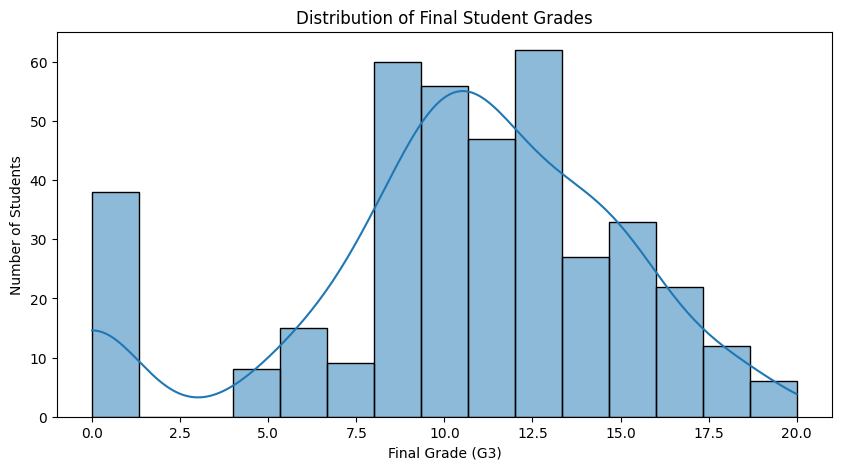

In [80]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='G3',
    bins=15,
    kde=True
)

plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

In [81]:
zero_grades = (df['G3'] == 0).sum()

print("Students with zero grades:", zero_grades)

print(
    "Percentage:",
    (zero_grades / len(df)) * 100
)

Students with zero grades: 38
Percentage: 9.620253164556962


In [82]:
print("Skewness:", df['G3'].skew())

print("Zero grades:", (df['G3'] == 0).sum())

print("Grade distribution:")
print(df['G3'].value_counts().sort_index())

Skewness: -0.7326723530443435
Zero grades: 38
Grade distribution:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


5.3 Study Time vs Final Grades

This analysis investigates the relationship between students' weekly study time and their final Mathematics grades ("G3").

The "studytime" variable represents weekly study time using four categories:

| Category | Weekly Study Time |
| :---: | :--- |
| 1 | Less than 2 hours |
| 2 | 2 to 5 hours |
| 3 | 5 to 10 hours |
| 4 | More than 10 hours |

The average final grade is calculated for each study-time category using grouping and aggregation techniques.

A comparison of these averages helps examine whether students with different study-time patterns demonstrate differences in academic performance.

The analysis is exploratory and does not establish a causal relationship between study time and final grades.

In [83]:
study_analysis = df.groupby('studytime')['G3'].mean()

print(study_analysis)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


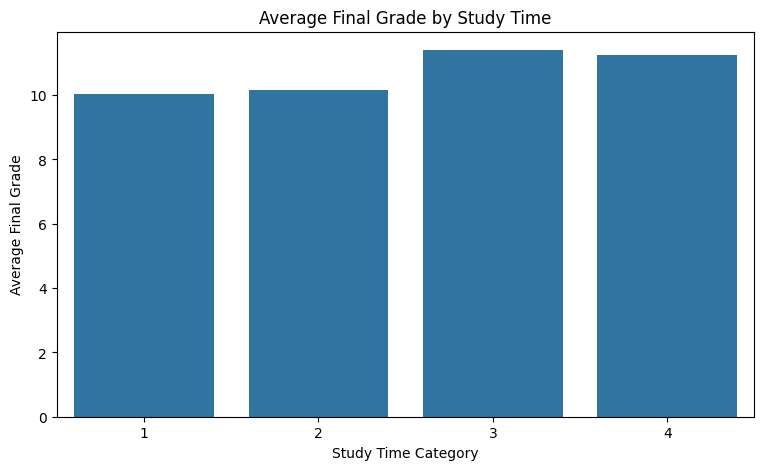

In [84]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='studytime',
    y='G3',
    errorbar=None
)

plt.title('Average Final Grade by Study Time')
plt.xlabel('Study Time Category')
plt.ylabel('Average Final Grade')

plt.show()

In [85]:
print(df['studytime'].value_counts().sort_index())

studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


5.4 Absences vs Final Grades

This analysis examines the relationship between the number of school absences and students' final Mathematics grades ("G3").

The "absences" variable represents the number of school absences recorded for each student.

The analysis uses:

- Scatter Plot: To visualize the relationship between absences and final grades and identify possible patterns or unusual observations.
- Pearson Correlation: To measure the strength and direction of the linear relationship between the two variables.

The correlation coefficient ranges from -1 to +1:

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear correlation.

This analysis helps determine whether school attendance has a noticeable linear association with academic performance.

In [86]:
absence_analysis = df.groupby('absences')['G3'].mean()

print(f"{absence_analysis}\n")

absence_analysis_1 = df.groupby('absences').agg(
    average_G3=('G3', 'mean'),
    student_count=('G3', 'count')
)

print(absence_analysis_1)

absences
0      8.443478
1     13.000000
2     11.907692
3     11.500000
4     11.283019
5     11.600000
6     11.774194
7     11.857143
8     10.590909
9     13.333333
10    11.235294
11    11.666667
12    10.750000
13    12.666667
14     9.333333
15     8.333333
16     9.857143
17    10.000000
18     8.400000
19    10.000000
20    11.500000
21    18.000000
22     8.000000
23    13.000000
24    18.000000
25    11.000000
26     6.000000
28     9.000000
30     8.000000
38     8.000000
40    11.000000
54    11.000000
56     8.000000
75     9.000000
Name: G3, dtype: float64

          average_G3  student_count
absences                           
0           8.443478            115
1          13.000000              3
2          11.907692             65
3          11.500000              8
4          11.283019             53
5          11.600000              5
6          11.774194             31
7          11.857143              7
8          10.590909             22
9          13.333333     

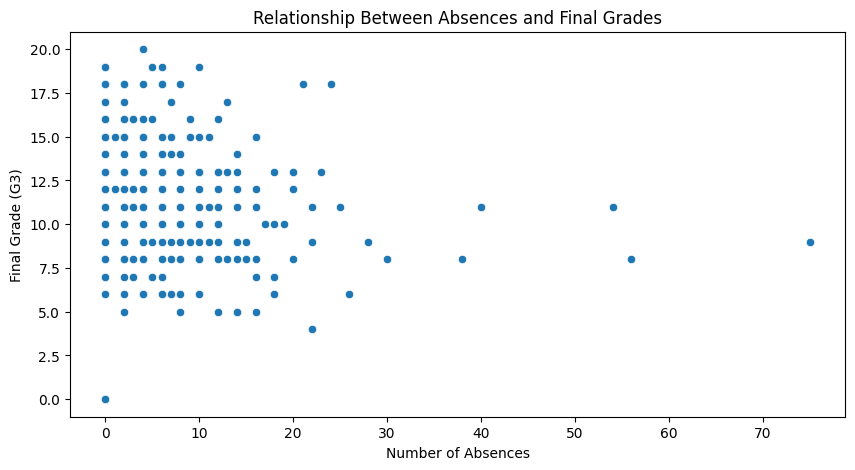

In [87]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='absences',
    y='G3'
)

plt.title('Relationship Between Absences and Final Grades')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade (G3)')

plt.show()

In [88]:
correlation = df['absences'].corr(df['G3'])

print("Correlation:", correlation)

Correlation: 0.03424731615006931


5.5 Correlation Analysis

Correlation analysis is performed to understand the strength and direction of relationships between numerical variables in the dataset.

Pearson correlation coefficients are calculated to examine how individual features are linearly associated with the final Mathematics grade ("G3").

Correlation Coefficient

The Pearson correlation coefficient ranges from -1 to +1:

- Positive correlation: Both variables tend to increase together.
- Negative correlation: One variable tends to decrease as the other increases.
- Near-zero correlation: Little or no linear relationship.

Correlation Heatmap

A correlation heatmap is generated to visualize relationships between numerical variables.

It helps identify:

- Features strongly associated with the target variable.
- Relationships between independent variables.
- Potential multicollinearity among predictive features.

Correlation indicates association, not causation. Furthermore, a low Pearson correlation does not necessarily mean that a feature has no predictive value.

In [89]:
correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix)

                 age      Medu      Fedu  traveltime  studytime  failures  \
age         1.000000 -0.163658 -0.163438    0.070641  -0.004140  0.243665   
Medu       -0.163658  1.000000  0.623455   -0.171639   0.064944 -0.236680   
Fedu       -0.163438  0.623455  1.000000   -0.158194  -0.009175 -0.250408   
traveltime  0.070641 -0.171639 -0.158194    1.000000  -0.100909  0.092239   
studytime  -0.004140  0.064944 -0.009175   -0.100909   1.000000 -0.173563   
failures    0.243665 -0.236680 -0.250408    0.092239  -0.173563  1.000000   
famrel      0.053940 -0.003914 -0.001370   -0.016808   0.039731 -0.044337   
freetime    0.016434  0.030891 -0.012846   -0.017025  -0.143198  0.091987   
goout       0.126964  0.064094  0.043105    0.028540  -0.063904  0.124561   
Dalc        0.131125  0.019834  0.002386    0.138325  -0.196019  0.136047   
Walc        0.117276 -0.047123 -0.012631    0.134116  -0.253785  0.141962   
health     -0.062187 -0.046878  0.014742    0.007501  -0.075616  0.065827   

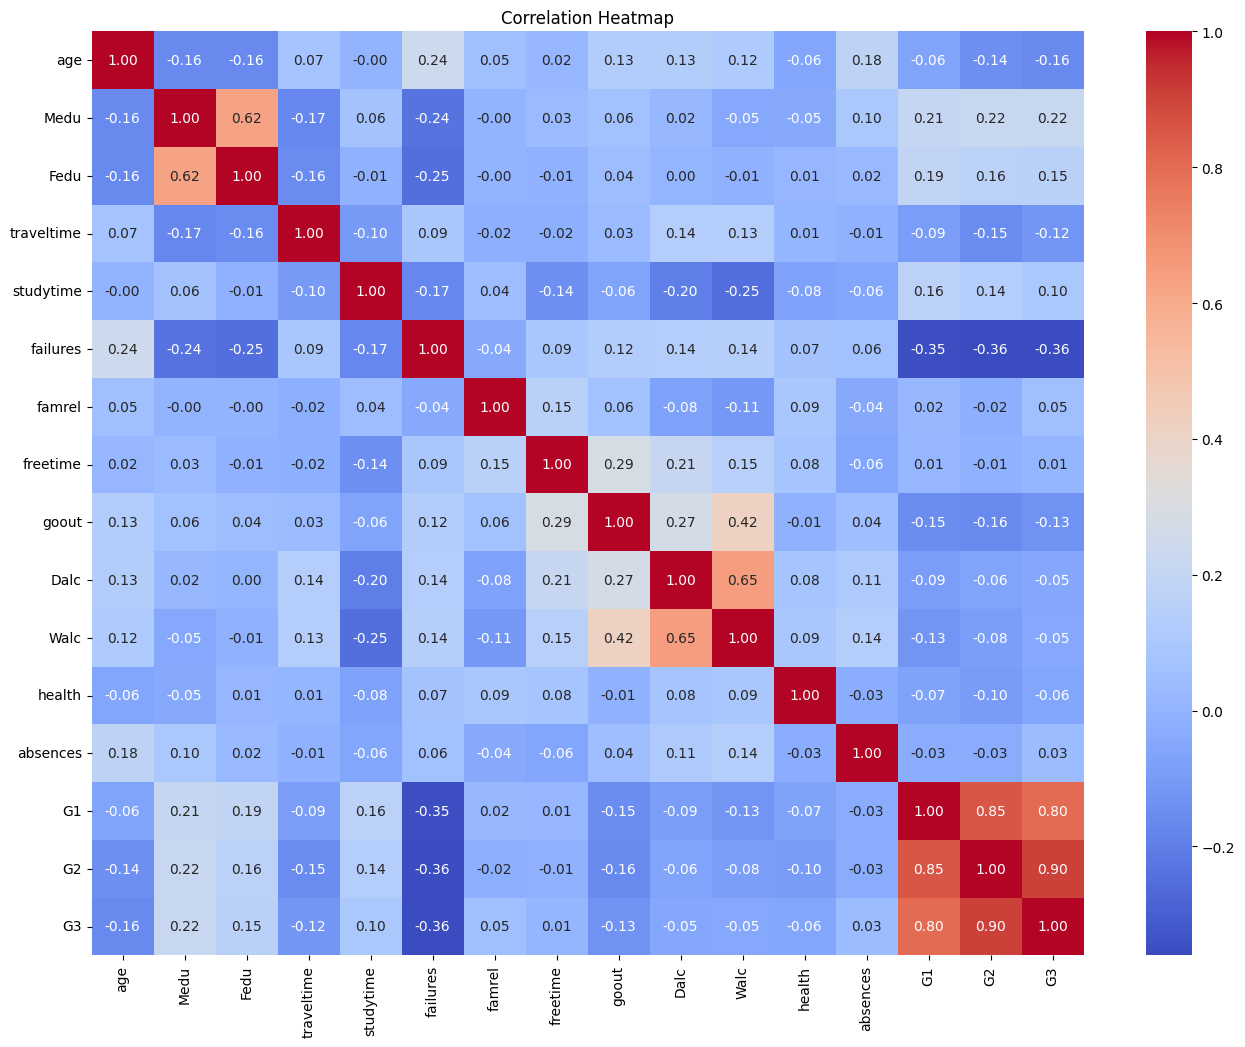

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [91]:
g3_correlation = correlation_matrix['G3'].sort_values(
    ascending=False
)

print(g3_correlation)


G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


5.6 Multicollinearity Analysis Using Variance Inflation Factor (VIF)

After examining the correlation matrix, Variance Inflation Factor (VIF) is calculated to investigate multicollinearity among the independent variables.

Multicollinearity occurs when two or more independent variables are highly correlated with each other. This can make regression coefficients unstable and difficult to interpret.

Variance Inflation Factor

VIF measures how much the variance of an estimated regression coefficient is increased due to multicollinearity.

The VIF value is calculated using:

$$\text{VIF} = \frac{1}{1 - R^2}$$

Where $R^2$ represents the coefficient of determination obtained by regressing one independent variable against the remaining independent variables.

Interpretation of VIF

| VIF Value | Interpretation |
| :---: | :--- |
| 1 | No multicollinearity |
| 1–5 | Generally acceptable |
| 5–10 | Potential multicollinearity |
| Above 10 | High multicollinearity concern |

These are general guidelines rather than strict statistical rules.

VIF helps identify features that may create multicollinearity problems, particularly when developing regression models.

In [92]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[['G1', 'G2', 'studytime', 'failures']]

vif_data = pd.DataFrame()

vif_data['Feature'] = X.columns

vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data)

     Feature       VIF
0         G1  3.711842
1         G2  3.696378
2  studytime  1.043396
3   failures  1.176923


6. Feature and Target Separation

Before developing machine learning models, the dataset is divided into independent variables (features) and the dependent variable (target).

6.1 Independent Variables (X)

The independent variables contain the information used by machine learning models to make predictions.

The "G3" column is removed from the original DataFrame using the "drop()" function.

6.2 Dependent Variable (y)

The dependent variable contains the value that the model is expected to predict.

In this project, "G3" represents the student's final Mathematics grade and is selected as the target variable.

6.3 Objective

The objective is to train regression models using the available student-related features to predict their final Mathematics grades.

Separating X and y ensures that the target variable is not accidentally included among the model inputs, which would cause target leakage.

In [93]:
X = df.drop('G3', axis=1)

y = df['G3']

In [94]:
# Keep only numerical columns and separate them from the G3 target variable
X = df.select_dtypes(include='number')
X = X.drop(columns=['G3'])

7. Feature Correlation and Selection

After separating the independent variables ("X") and the target variable ("y"), individual feature correlations with the target are examined.

7.1 Feature-wise Correlation

The Pearson correlation coefficient is calculated between each independent variable and the target variable "G3".

This helps identify which features have stronger positive or negative linear relationships with final Mathematics grades.

7.2 Absolute Correlation Values

The absolute values of the correlation coefficients are calculated to compare the strength of relationships without considering their direction.

Features are then sorted according to their absolute correlation values.

7.3 Feature Comparison

The correlation values are examined to understand the relative association of individual features with the target variable.

This provides an initial statistical perspective on potentially useful predictive features.

Note: Correlation-based analysis is used as an exploratory feature assessment technique. Features with low individual correlation are not automatically considered irrelevant, as they may still contribute useful information when combined with other variables.

In [95]:
correlation = X.corrwith(y)

selected_features = correlation[
    correlation.abs() > 0.10
]

print(selected_features)

age          -0.161579
Medu          0.217147
Fedu          0.152457
traveltime   -0.117142
failures     -0.360415
goout        -0.132791
G1            0.801468
G2            0.904868
dtype: float64


8. Feature Selection Using Lasso Regression

Lasso (Least Absolute Shrinkage and Selection Operator) is a regularization technique that can be used for both regression and feature selection.

It applies an L1 penalty to the regression coefficients, encouraging less important coefficients to become exactly zero.

8.1 Feature Scaling

StandardScaler is applied to standardize the independent variables.

Standardization transforms features to have approximately:

- Mean = 0
- Standard deviation = 1

This is important because Lasso penalizes coefficient magnitudes, and features with different scales could otherwise influence the regularization process unevenly.

8.2 Lasso Regularization

Lasso minimizes the following objective function:

Minimize:

RSS + α Σ|βⱼ|

Where:

- RSS represents the residual sum of squares.
- α controls the strength of regularization.
- βⱼ represents the regression coefficients.

As the regularization strength increases, coefficients shrink, and some may become exactly zero.

8.3 SelectFromModel

SelectFromModel is used with the fitted Lasso estimator to identify features based on their coefficient magnitudes.

The "get_support()" method returns a Boolean mask indicating which features satisfy the selection threshold.

8.4 Selected Feature Analysis

The selected features are extracted and compared with the correlation-based feature analysis.

This provides two different perspectives on feature selection:

- Correlation-based analysis examines individual linear relationships.
- Lasso considers features together while applying regularization.

In [96]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel

# Standardize features before applying Lasso to ensure fair penalty scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Run Lasso regression to identify and select the most impactful features
lasso = Lasso(alpha=0.1)
lasso.fit(X_scaled, y)

# Filter out features with coefficients shrunk to absolute zero
selector = SelectFromModel(lasso, prefit=True)
selected = X.columns[selector.get_support()]

print("Selected Features:")
print(selected)

Selected Features:
Index(['age', 'studytime', 'failures', 'famrel', 'Walc', 'absences', 'G1',
       'G2'],
      dtype='object')


9. Comparison of Feature Selection Methods

In this section, two feature selection approaches are compared:

1. Correlation-Based Selection: Identifies features based on their individual correlation with the target variable ("G3").
2. Lasso-Based Selection: Uses L1 regularization to reduce less important feature coefficients to zero.

The selected features from both approaches are compared using a DataFrame and visualization.

Purpose

- Identify features selected by both methods.
- Observe differences between the two selection approaches.
- Understand how individual correlation differs from a regularized model-based approach.

Key Observation

Features selected by both methods may be useful candidates for prediction. However, neither method alone guarantees the best predictive performance. The final feature set should be evaluated using an appropriate train-test validation process.

In [97]:
correlation = X.corrwith(y)

lasso_results = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso.coef_
})

feature_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Correlation': correlation.values,
    'Coefficient': lasso.coef_
})

feature_comparison['Selected by Lasso'] = (
    feature_comparison['Coefficient'] != 0
)

feature_comparison = feature_comparison.sort_values(
    by='Correlation',
    key=abs,
    ascending=False
)

display(feature_comparison)

,Feature,Correlation,Coefficient,Selected by Lasso
14,G2,0.904868,3.625325,True
13,G1,0.801468,0.451324,True
5,failures,-0.360415,-0.081845,True
1,Medu,0.217147,0.000000,False
0,age,-0.161579,-0.124574,True
2,Fedu,0.152457,-0.000000,False
8,goout,-0.132791,0.000000,False
3,traveltime,-0.117142,0.000000,False
4,studytime,0.097820,-0.015946,True
11,health,-0.061335,0.000000,False


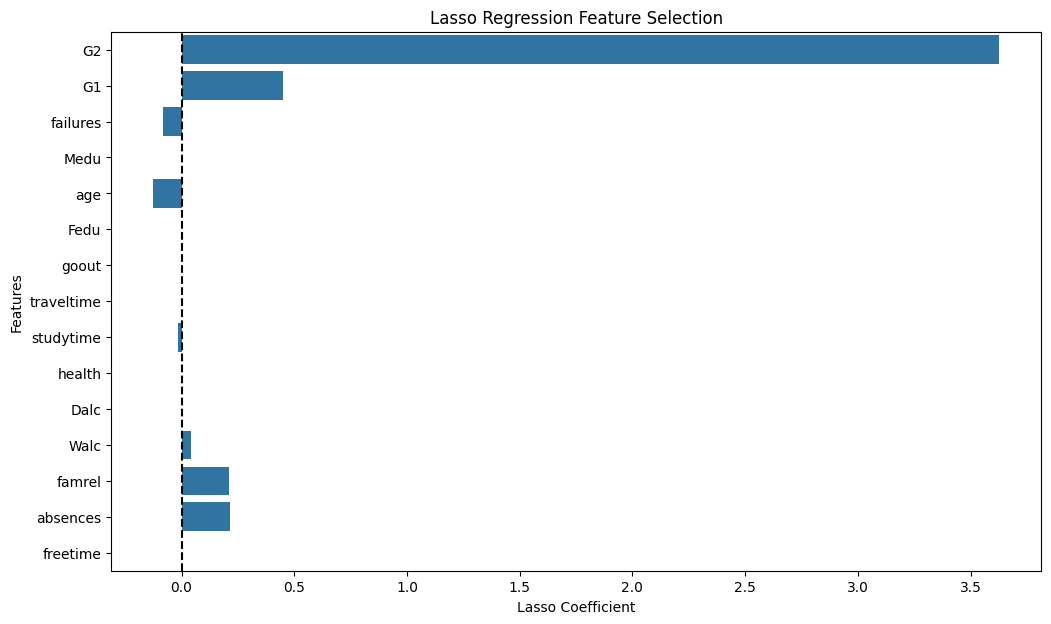

In [98]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_comparison,
    x='Coefficient',
    y='Feature'
)

plt.axvline(0, color='black', linestyle='--')
plt.title('Lasso Regression Feature Selection')
plt.xlabel('Lasso Coefficient')
plt.ylabel('Features')
plt.show()

10. Splitting the Dataset into Training and Testing Sets

Before training machine learning models, the dataset is divided into two subsets:

- Training Set (80%): Used to train the machine learning models.
- Testing Set (20%): Used to evaluate how well the trained models perform on unseen data.

The "train_test_split()" function from Scikit-learn is used for this purpose.

Parameters

- "test_size = 0.2": Allocates 20% of the data for testing.
- "random_state = 42": Ensures reproducibility by generating the same split each time.

Dataset Distribution

- Total observations: 395
- Training observations: 316
- Testing observations: 79

Purpose

Separating training and testing data helps evaluate the model's ability to generalize to unseen observations rather than simply memorizing the training data.

In [99]:
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing sets using a fixed seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [100]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316, 15)
X_test: (79, 15)
y_train: (316,)
y_test: (79,)


11. Feature Scaling Using StandardScaler

Feature scaling is a preprocessing technique that brings numerical features to a comparable scale. It is particularly important for algorithms such as Linear Regression with regularization (Ridge and Lasso), where differences in feature magnitudes can affect model performance.

In this project, "StandardScaler" from Scikit-learn is used to standardize the features.

Standardization Formula

[
Z = \frac{X-\mu}{\sigma}
]

Where:

- X = Original feature value
- \mu = Mean of the feature
- \sigma = Standard deviation of the feature
- Z = Standardized value

After standardization, each feature has approximately:

- Mean = 0
- Standard deviation = 1

Implementation

The scaler is fitted only on the training data using "fit_transform()". The same fitted scaler is then applied to the testing data using "transform()".

This prevents data leakage because information from the testing set is not used to calculate the scaling parameters.

Important Note

The scaled datasets are used for models that benefit from feature standardization. Tree-based models such as Random Forest generally do not require feature scaling.

In [101]:
from sklearn.preprocessing import StandardScaler

# Fit standardizer on training set only, then scale both training and testing sets
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [102]:
print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

print("Testing shape:", X_test_scaled.shape)

Training mean: -4.6657473946272404e-17
Training standard deviation: 1.0
Testing shape: (79, 15)


# 12. Model Building: Linear Regression

Linear Regression is used as the first baseline machine learning model to predict students' final Mathematics grades ("G3").

It is a supervised learning algorithm that models the relationship between input features and a continuous target variable.

Working Principle

Linear Regression predicts the target value using a linear combination of input features.

$$\hat{y} = \beta_0 + \beta_1X_1 + \beta_2X_2 + \cdots + \beta_nX_n$$

Where:

- $\hat{y}$ = Predicted final grade
- $\beta_0$ = Intercept
- $\beta_1, \beta_2, \ldots, \beta_n$ = Model coefficients
- $X_1, $X_2, \ldots, X_n$ = Input features

The model learns the coefficients by minimizing the sum of squared differences between actual and predicted values.

Model Training and Prediction

The Linear Regression model is trained using the scaled training dataset. It then generates predictions on the scaled testing dataset.

Evaluation Metrics

The model is evaluated using three metrics:

- Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted grades. Lower values indicate better performance.
- Root Mean Squared Error (RMSE): Measures prediction error while penalizing larger errors more heavily. Lower values are better.
- $R^2$ Score: Measures how much of the variation in the target variable is explained by the model. A value closer to 1 indicates a better fit.

Purpose

Linear Regression establishes a baseline performance against which more advanced models can be compared.

In [103]:
from sklearn.linear_model import LinearRegression

# Train a baseline Linear Regression model using our scaled features
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [104]:
y_pred_lr = lr_model.predict(X_test_scaled)

print(y_pred_lr[:10])

[ 5.97177162 12.0630197   3.15526907  9.13540476  7.68924173 12.01454663
 18.95862182  7.06990931  7.39898904 12.74936974]


In [105]:
comparison = pd.DataFrame({
    'Actual Grade': y_test.values[:10],
    'Predicted Grade': y_pred_lr[:10]
})

display(comparison)

,Actual Grade,Predicted Grade
0,10,5.971772
1,12,12.063020
2,5,3.155269
3,10,9.135405
4,9,7.689242
5,13,12.014547
6,18,18.958622
7,6,7.069909
8,0,7.398989
9,14,12.749370


In [106]:
lr_coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
})

lr_coefficients = lr_coefficients.sort_values(
    by='Coefficient',
    key=abs,
    ascending=False
)

display(lr_coefficients)

,Feature,Coefficient
14,G2,3.665736
13,G1,0.516278
12,absences,0.377251
5,failures,-0.305709
6,famrel,0.295818
0,age,-0.251119
2,Fedu,-0.202797
8,goout,0.153833
1,Medu,0.101604
9,Dalc,-0.094702


In [107]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate regression metrics to evaluate model predictions on unseen test data
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Evaluation")
print("MAE:", mae_lr)
print("MSE:", mse_lr)
print("RMSE:", rmse_lr)
print("R² Score:", r2_lr)

Linear Regression Evaluation
MAE: 1.3481637884413586
MSE: 4.5037691537195785
RMSE: 2.1222085556607246
R² Score: 0.7803580213768333


# 13. Model Building: Ridge Regression

Ridge Regression is a regularized version of Linear Regression. It uses L2 regularization to reduce the magnitude of model coefficients and help control overfitting.

Working Principle

Ridge Regression adds a penalty term to the ordinary least squares objective function.

$$J(\beta) = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2 + \alpha\sum_{j=1}^{p}\beta_j^2$$

Where:

- $y_i$ = Actual target value
- $\hat{y}_i$ = Predicted target value
- $\beta_j$ = Model coefficients
- $\alpha$ = Regularization strength

A larger value of $\alpha$ applies a stronger penalty to large coefficients.

Model Training and Prediction

The Ridge Regression model is trained using the scaled training dataset. It then predicts final Mathematics grades on the scaled testing dataset.

Evaluation

The model is evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- $R^2$ Score

Its performance is compared with the baseline Linear Regression model to examine whether regularization improves prediction accuracy.

Purpose

Ridge Regression helps investigate whether controlling coefficient magnitude improves the model's ability to generalize to unseen student records.

In [108]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

Ridge()

In [109]:
y_pred_ridge = ridge_model.predict(X_test_scaled)

In [110]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Evaluation")
print("MAE:", mae_ridge)
print("MSE:", mse_ridge)
print("RMSE:", rmse_ridge)
print("R² Score:", r2_ridge)


Ridge Regression Evaluation
MAE: 1.3474164133688764
MSE: 4.500487484965965
RMSE: 2.1214352417563833
R² Score: 0.7805180633757964


# 14. Model Building: Lasso Regression

Lasso Regression is another regularized version of Linear Regression. It uses L1 regularization to penalize large coefficients and can shrink some coefficients exactly to zero.

Unlike Ridge Regression, which generally retains all features, Lasso can perform feature selection by eliminating less influential features.

Working Principle

Lasso adds an L1 penalty to the ordinary least squares objective function.

$$J(\beta) = \sum_{i=1}^{n}(y_i-\hat{y}_i)^2 + \alpha\sum_{j=1}^{p}|\beta_j|$$

Where:

- $y_i$ = Actual target value
- $\hat{y}_i$ = Predicted target value
- $\beta_j$ = Model coefficients
- $\alpha$ = Regularization strength

Model Training and Prediction

The Lasso model is trained using the scaled training dataset and evaluated on the scaled testing dataset.

Evaluation

Its performance is measured using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- $R^2$ Score

The results are compared with Linear Regression and Ridge Regression to determine how L1 regularization affects predictive performance.

Purpose

This experiment examines whether L1 regularization improves prediction accuracy and whether reducing less influential coefficients helps the model generalize to unseen data.

In [111]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train_scaled, y_train)

Lasso(alpha=0.1)

In [112]:
y_pred_lasso = lasso_model.predict(X_test_scaled)

In [113]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Evaluation")
print("MAE:", mae_lasso)
print("MSE:", mse_lasso)
print("RMSE:", rmse_lasso)
print("R² Score:", r2_lasso)

Lasso Regression Evaluation
MAE: 1.2687919137205015
MSE: 4.337977392733267
RMSE: 2.082781167749811
R² Score: 0.788443433656985


In [114]:
lasso_coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso_model.coef_
})

display(
    lasso_coefficients[
        lasso_coefficients['Coefficient'] != 0
    ].sort_values(
        by='Coefficient',
        key=abs,
        ascending=False
    )
)

,Feature,Coefficient
14,G2,3.617814
13,G1,0.435783
12,absences,0.257512
5,failures,-0.219167
6,famrel,0.213941
0,age,-0.135875
8,goout,0.044662
3,traveltime,0.002672


# 15. Model Building: Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines multiple Decision Trees to make predictions.

Instead of relying on a single decision tree, it builds several trees using randomly selected samples and features from the training dataset. The final prediction is obtained by averaging the predictions of all individual trees.

Working Principle

1. Multiple subsets of the training data are created using bootstrap sampling.
2. A separate Decision Tree is trained on each subset.
3. At each split, a random subset of features is considered.
4. Predictions from all trees are combined by calculating their average.

Prediction Formula

$$\hat{y} = \frac{1}{N}\sum_{i=1}^{N}T_i(x)$$

Where:

- $N$ = Number of decision trees
- $T_i(x)$ = Prediction made by the $i^{th}$ tree
- $\hat{y}$ = Final predicted value

Model Training and Evaluation

The Random Forest model is trained using the training dataset and generates predictions on the testing dataset.

Its performance is evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- $R^2$ Score

Purpose

Random Forest can capture nonlinear relationships and interactions between features. This experiment investigates whether an ensemble of decision trees can predict student performance more accurately than the previously tested linear models.

In [115]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest with 300 decision trees to handle non-linear patterns
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=300, random_state=42)

In [116]:
y_pred_rf = rf_model.predict(X_test)

16. Random Forest Model Evaluation

After training the Random Forest Regressor, its predictive performance is evaluated using the testing dataset.

Three evaluation metrics are used:

- Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted grades.
- Root Mean Squared Error (RMSE): Measures the square root of the average squared prediction errors, giving greater weight to larger errors.
- $R^2$ Score: Indicates the proportion of variation in the target variable explained by the model.

Results

The Random Forest model achieved the following results on the testing dataset:

| Metric | Score |
| :--- | :---: |
| MAE | 1.0482 |
| RMSE | 1.7359 |
| $R^2$ Score | 0.8530 |

Observation

The model achieved an $R^2$ score of approximately 0.85, indicating that it explains around 85.3% of the variation in final student grades within the test set.

The relatively low MAE indicates that its predictions are, on average, close to the actual grades. However, individual predictions may still contain significant errors.

In [117]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Evaluation")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

Random Forest Evaluation
MAE: 1.048185654008439
MSE: 3.013259634317863
RMSE: 1.7358743140901252
R² Score: 0.853047905965541


In [118]:
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

display(
    rf_importance.sort_values(
        by='Importance',
        ascending=False
    )
)

,Feature,Importance
14,G2,0.787894
12,absences,0.116548
0,age,0.024855
6,famrel,0.012152
11,health,0.011256
13,G1,0.009224
2,Fedu,0.008189
8,goout,0.006961
7,freetime,0.004296
10,Walc,0.003750


17. Training vs Testing R² Analysis

After evaluating the Random Forest model, its R² scores on the training and testing datasets are compared.

This comparison helps assess how well the model learns patterns from the training data and how effectively it generalizes to unseen observations.

Evaluation

- Training R²: Measures the model's explanatory performance on the training dataset.
- Testing R²: Measures the model's explanatory performance on the testing dataset.

Results

- Training R² Score: 0.9846
- Testing R² Score: 0.8530

Observation

The training R² score is higher than the testing R² score, indicating a difference in model performance between the two datasets.

This suggests that the Random Forest model exhibits some overfitting. However, its testing R² score indicates that it still explains a substantial proportion of the variation in unseen student records.

This comparison provides a reason to investigate whether hyperparameter tuning can improve the model's generalization performance.

In [119]:
train_r2_rf = rf_model.score(X_train, y_train)
test_r2_rf = rf_model.score(X_test, y_test)

print("Training R²:", train_r2_rf)
print("Testing R²:", test_r2_rf)

Training R²: 0.9846113868086946
Testing R²: 0.853047905965541


18. Random Forest with Restricted Hyperparameters

After evaluating the initial Random Forest model, a second Random Forest Regressor is created with manually restricted hyperparameter values.

The objective is to control the complexity of individual decision trees and investigate whether limiting their growth can reduce overfitting.

Hyperparameters Adjusted

- max_depth: Limits the maximum depth of each decision tree.
- min_samples_split: Specifies the minimum number of samples required to split an internal node.
- min_samples_leaf: Specifies the minimum number of samples required at a leaf node.

Working Principle

By restricting tree depth and increasing the minimum number of samples required for splitting and leaf formation, the model is prevented from creating excessively complex trees.

The modified Random Forest model is trained on the training dataset and evaluated on the testing dataset.

Purpose

This experiment examines whether manually controlling tree complexity can improve the balance between training performance and generalization to unseen student records.

In [120]:
# Define a tuned Random Forest with depth limits and leaf splits to prevent overfitting
rf_tuned = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

rf_tuned.fit(X_train, y_train)

y_pred_rf_tuned = rf_tuned.predict(X_test)

19. Evaluation of Random Forest with Restricted Hyperparameters

After modifying the Random Forest hyperparameters, the model is evaluated to examine the effect of limiting decision tree complexity.

Evaluation Metrics

The model is assessed using the following metrics:

- Training R²: Measures the model's performance on training data.
- Testing R²: Measures its performance on unseen testing data.
- Mean Absolute Error (MAE): Measures the average absolute prediction error.
- Root Mean Squared Error (RMSE): Measures prediction error while giving greater weight to larger errors.
- R² Score: Measures the proportion of variation in final grades explained by the model.

Purpose

The results are compared with the initial Random Forest model to determine whether restricting tree complexity reduces overfitting and improves predictive performance.

The comparison also helps identify the trade-off between fitting the training data and generalizing to unseen observations.

In [121]:
print("Training R²:", rf_tuned.score(X_train, y_train))
print("Testing R²:", rf_tuned.score(X_test, y_test))

print("MAE:", mean_absolute_error(y_test, y_pred_rf_tuned))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned)))
print("R²:", r2_score(y_test, y_pred_rf_tuned))

Training R²: 0.9696219069225375
Testing R²: 0.8520520269410446
MAE: 1.0696374596063891
RMSE: 1.7417463020739952
R²: 0.8520520269410446


20. Comparative Analysis of Machine Learning Models

After training and evaluating the four models, their performance is compared using a common set of evaluation metrics.

Models Compared

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Random Forest Regressor

Evaluation Metrics

- Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted grades. Lower values indicate better performance.
- Root Mean Squared Error (RMSE): Measures prediction errors while penalizing larger errors more heavily. Lower values are preferred.
- R² Score: Measures how much variation in the target variable is explained by the model. Higher values indicate better performance.

Purpose

A comparative analysis helps identify which algorithm performs best on the testing dataset.

It also highlights the differences between linear models and tree-based ensemble learning methods when predicting student academic performance.

The comparison is based on test-set results to ensure that all four models are evaluated on the same unseen observations.

In [122]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge', 'Lasso', 'Random Forest'],
    'MAE': [mae_lr, mae_ridge, mae_lasso, mae_rf],
    'MSE': [mse_lr, mse_ridge, mse_lasso, mse_rf],
    'RMSE': [rmse_lr, rmse_ridge, rmse_lasso, rmse_rf],
    'R2 Score': [r2_lr, r2_ridge, r2_lasso, r2_rf]
})

display(model_comparison.sort_values(by='R2 Score', ascending=False))

,Model,MAE,MSE,RMSE,R2 Score
3,Random Forest,1.048186,3.013260,1.735874,0.853048
2,Lasso,1.268792,4.337977,2.082781,0.788443
1,Ridge,1.347416,4.500487,2.121435,0.780518
0,Linear Regression,1.348164,4.503769,2.122209,0.780358


21. Cross-Validation of Random Forest Model

A single train-test split may not fully represent how consistently a machine learning model performs on different subsets of data.

To obtain a more reliable estimate of model performance, cross-validation is performed on the training dataset.

K-Fold Cross-Validation

In this experiment, 5-Fold Cross-Validation is used.

The training dataset is divided into five approximately equal folds:

1. The model is trained on four folds.
2. The remaining fold is used for validation.
3. This process is repeated five times, with each fold serving as the validation set once.
4. The five validation scores are averaged to obtain the mean cross-validation score.

Evaluation Metric

The R² score is used to evaluate model performance across the five folds.

The following values are examined:

- Individual fold R² scores.
- Mean cross-validation R² score.
- Standard deviation of the scores.

Purpose

Cross-validation helps assess the stability of the model across different data partitions and provides a better understanding of its generalization performance.

Note: Cross-validation is performed on the training dataset, keeping the testing dataset separate for final model evaluation.

In [123]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation to assess how consistently our Random Forest performs
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

print("Individual R² Scores:", cv_scores)
print("Mean R²:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Individual R² Scores: [0.91153325 0.91602459 0.91789123 0.85917521 0.84421905]
Mean R²: 0.8897686680917767
Standard Deviation: 0.031510875026933956


22. Hyperparameter Optimization Using GridSearchCV

After performing cross-validation, GridSearchCV is used to search systematically for an effective combination of Random Forest hyperparameters.

Unlike manual hyperparameter tuning, GridSearchCV evaluates multiple combinations from a predefined parameter grid and selects the combination with the best cross-validation performance.

Working Principle

1. Define a parameter grid containing different hyperparameter values.
2. Generate combinations of the specified values.
3. Evaluate each combination using 5-fold cross-validation.
4. Compare the validation scores.
5. Select the combination with the best average performance.

Hyperparameters Considered

- "n_estimators": Number of decision trees.
- "max_depth": Maximum depth of each tree.
- "max_features": Number of features considered when searching for the best split.
- "min_samples_split": Minimum samples required to split an internal node.
- "min_samples_leaf": Minimum samples required at a leaf node.

Scoring Method

Negative Root Mean Squared Error ("neg_root_mean_squared_error") is used as the scoring metric.

GridSearchCV maximizes this negative score, which corresponds to selecting the model with the lowest actual RMSE.

Purpose

The objective is to identify a suitable combination of hyperparameters that minimizes prediction error and improves the model's generalization performance.

In [124]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [200, 400],
    'max_depth': [None, 8, 12],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': [1.0, 'sqrt']
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 8, 12],
                         'max_features': [1.0, 'sqrt'],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [200, 400]},
             scoring='neg_root_mean_squared_error', verbose=1)

23. Best Hyperparameters Identified by GridSearchCV

After evaluating the different hyperparameter combinations using 5-fold cross-validation, GridSearchCV identifies the combination that achieves the best validation performance.

Best Parameters

The optimal hyperparameter combination is obtained using the "best_params_" attribute.

The best cross-validation score is obtained using the "best_score_" attribute.

Best Cross-Validation Result

- Best CV RMSE: 1.4946
- Cross-validation folds: 5
- Total parameter combinations: 48
- Total model fits: 240

Purpose

These results identify the hyperparameter configuration that performed best during cross-validation.

The selected configuration is then used to evaluate the optimized Random Forest model on the testing dataset.

In [125]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

Best Parameters: {'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV RMSE: 1.494629056772427


24. Evaluation of GridSearchCV-Optimized Random Forest

After identifying the best hyperparameter combination using GridSearchCV, the optimized Random Forest model is evaluated on the testing dataset.

The model uses the best parameters identified during cross-validation to generate predictions on previously unseen student records.

Evaluation Metrics

The optimized model is evaluated using:

- Mean Absolute Error (MAE): Measures the average absolute prediction error.
- Root Mean Squared Error (RMSE): Measures prediction error while penalizing larger errors.
- R² Score: Measures the proportion of variation in final grades explained by the model.

Purpose

The tuned model's performance is compared with the original Random Forest model to determine whether systematic hyperparameter optimization improves predictive accuracy and generalization.

A lower MAE and RMSE, together with a higher R² score, indicate better predictive performance.

However, hyperparameter tuning does not guarantee improvement on the testing dataset. The final decision should be based on the actual test-set results.

In [126]:
best_rf = grid_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_test)

mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
mse_best_rf = mean_squared_error(y_test, y_pred_best_rf)
rmse_best_rf = np.sqrt(mse_best_rf)
r2_best_rf = r2_score(y_test, y_pred_best_rf)

print("Tuned Random Forest Results")
print("MAE:", mae_best_rf)
print("MSE:", mse_best_rf)
print("RMSE:", rmse_best_rf)
print("R2:", r2_best_rf)

Tuned Random Forest Results
MAE: 1.0568468116328258
MSE: 3.056496931733448
RMSE: 1.7482839963042183
R2: 0.8509392886651108


In [127]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

train_rmse_rf = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
test_rmse_rf = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))

train_r2_rf = r2_score(y_train, y_train_pred_rf)
test_r2_rf = r2_score(y_test, y_test_pred_rf)

print("Training RMSE:", train_rmse_rf)
print("Testing RMSE:", test_rmse_rf)
print("Training R2:", train_r2_rf)
print("Testing R2:", test_r2_rf)

Training RMSE: 0.5685335344083368
Testing RMSE: 1.7358743140901252
Training R2: 0.9846113868086946
Testing R2: 0.853047905965541


25. Early Student Performance Prediction (Excluding G1 and G2)

In the previous experiments, the Random Forest model used all available input features, including "G1" (first-period grade) and "G2" (second-period grade).

However, these two features contain information about students' previous academic performance and may not be available when making predictions earlier in the academic year.

To investigate the possibility of earlier prediction, a separate Random Forest model is developed by excluding "G1" and "G2" from the input features.

Methodology

1. Remove "G1" and "G2" from the feature dataset.
2. Retain the remaining student-related features.
3. Train a Random Forest Regressor using the modified feature set.
4. Generate predictions on the testing dataset.
5. Evaluate the model using MAE, MSE, RMSE and R².

Purpose

The objective is to investigate how accurately student final grades can be predicted without relying on their first and second-period grades.

This experiment also helps understand how much predictive information is contributed by previous academic performance.

In [128]:
early_features = X.drop(columns=['G1', 'G2'])

X_train_early, X_test_early, y_train_early, y_test_early = train_test_split(
    early_features, y, test_size=0.2, random_state=42
)

early_rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

early_rf.fit(X_train_early, y_train_early)

y_pred_early = early_rf.predict(X_test_early)

early_mae = mean_absolute_error(y_test_early, y_pred_early)
early_rmse = np.sqrt(mean_squared_error(y_test_early, y_pred_early))
early_r2 = r2_score(y_test_early, y_pred_early)

print("Early Prediction Results")
print("MAE:", early_mae)
print("RMSE:", early_rmse)
print("R2:", early_r2)

Early Prediction Results
MAE: 3.3247888286116134
RMSE: 4.027547783019192
R2: 0.2089195927012002


26. Feature Importance Analysis of Early Prediction Model

After training the early prediction model, feature importance is analyzed to identify which remaining student-related variables contribute most to its predictions.

Since "G1" and "G2" have been excluded, this analysis focuses on the predictive contribution of the other available features.

Working Principle

Random Forest calculates feature importance based on how much each feature contributes to reducing impurity across the decision trees.

The importance scores are extracted from the trained model and sorted in descending order.

Purpose

- Identify the most influential features in early student performance prediction.
- Rank the remaining features according to their importance.
- Understand which student-related factors provide useful predictive information without relying on previous period grades.

Important Note

Feature importance indicates predictive contribution within the trained model. It does not establish a causal relationship between a feature and student performance.

In [129]:
early_importance = pd.Series(
    early_rf.feature_importances_,
    index=X_train_early.columns
).sort_values(ascending=False)

print(early_importance)

absences      0.214874
failures      0.151184
health        0.093239
goout         0.077667
age           0.073800
freetime      0.056323
Fedu          0.055556
studytime     0.052587
Medu          0.051435
traveltime    0.050611
Walc          0.050013
famrel        0.049890
Dalc          0.022821
dtype: float64


27. Visualization of Early Prediction Feature Importance

To make the feature importance results easier to interpret, a horizontal bar chart is created using the importance scores obtained from the early prediction Random Forest model.

Visualization Approach

- Features are arranged according to their importance scores.
- Higher scores indicate greater predictive contribution within the model.
- A horizontal bar chart is used to make comparisons between features easier.

Purpose

This visualization provides a clear ranking of the features that contribute most to early student performance prediction after excluding "G1" and "G2".

It also helps identify which remaining variables the model relies on most when estimating final Mathematics grades.

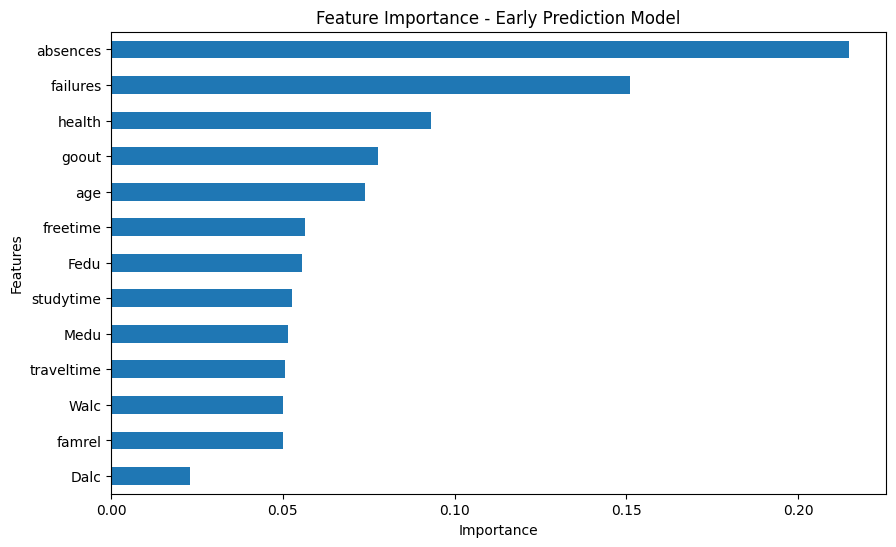

In [130]:
plt.figure(figsize=(10, 6))
early_importance.sort_values().plot(kind='barh')
plt.title("Feature Importance - Early Prediction Model")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

28. Permutation Feature Importance

Permutation Feature Importance is used to evaluate how much each input feature contributes to a model's predictive performance.

Unlike the built-in Random Forest feature importance, this method measures the change in model performance when the values of an individual feature are randomly shuffled.

Working Principle

1. Calculate the model's baseline performance on the testing dataset.
2. Randomly shuffle the values of one feature while keeping the other features unchanged.
3. Evaluate the model again using the modified dataset.
4. Measure the decrease in model performance.
5. Repeat the process and calculate the average importance score.

Interpretation

- Higher positive importance: Shuffling the feature reduces model performance, indicating that the feature provides useful predictive information.
- Importance near zero: The feature has little measurable effect on model performance.
- Negative importance: Shuffling the feature improves performance slightly, which may indicate noise or an unstable contribution.

Purpose

Permutation importance provides an alternative way to understand feature contributions and helps identify which variables are most useful for predicting student performance.

Important Note

Feature importance does not establish causation. Its results can also be influenced by correlated features and the evaluation dataset.

In [131]:
from sklearn.inspection import permutation_importance

perm_results = permutation_importance(
    early_rf,
    X_test_early,
    y_test_early,
    n_repeats=20,
    random_state=42,
    scoring='r2'
)

perm_importance = pd.Series(
    perm_results.importances_mean,
    index=X_test_early.columns
).sort_values(ascending=False)

print(perm_importance)

failures      0.270252
absences      0.233069
goout         0.127681
age           0.041029
Medu          0.039829
famrel        0.035111
freetime      0.016837
traveltime    0.015863
Walc          0.012731
Dalc         -0.001607
studytime    -0.002548
Fedu         -0.006333
health       -0.012838
dtype: float64


29. Visualization of Permutation Feature Importance

The permutation importance scores are visualized using a horizontal bar chart to make the contribution of individual features easier to compare.

Visualization Approach

- Features are arranged according to their permutation importance scores.
- Higher positive scores indicate a greater reduction in model performance when the corresponding feature is shuffled.
- Features with scores close to zero have relatively little measurable impact.
- Negative scores indicate that shuffling the feature slightly improved model performance.

Purpose

This visualization helps identify which features contribute most to the early prediction model's performance and provides an alternative perspective to the built-in Random Forest feature importance.

Comparing both methods helps develop a more complete understanding of the model's feature dependencies.

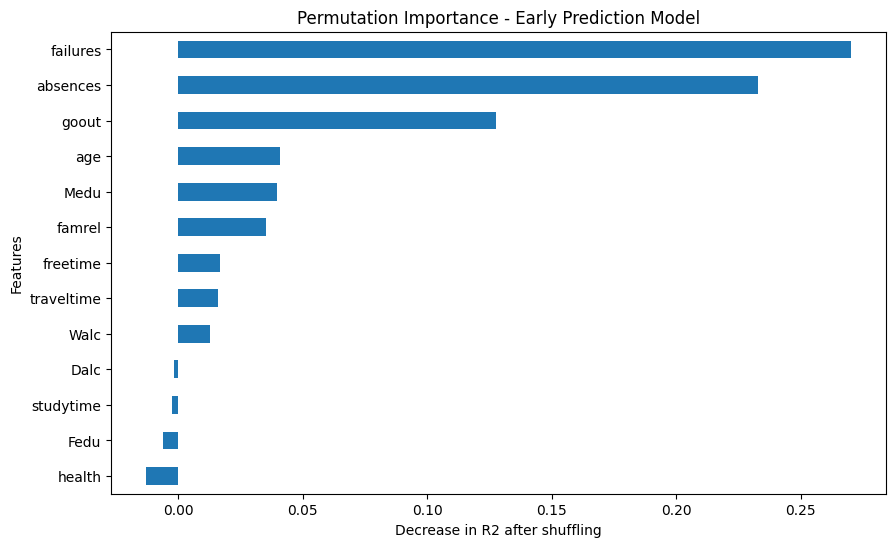

In [132]:
plt.figure(figsize=(10, 6))
perm_importance.sort_values().plot(kind='barh')
plt.title("Permutation Importance - Early Prediction Model")
plt.xlabel("Decrease in R2 after shuffling")
plt.ylabel("Features")
plt.show()

30. Final Comparative Analysis of All Five Models

After completing the model-building and evaluation experiments, all five models are compared using their testing performance.

Models Compared

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Random Forest Regressor
5. Tuned Random Forest Regressor
6. Early Prediction Random Forest Regressor (excluding "G1" and "G2")

Evaluation Metrics

The models are compared using three performance metrics:

- MAE (Mean Absolute Error): Measures the average absolute prediction error. Lower values are better.
- RMSE (Root Mean Squared Error): Penalizes larger prediction errors more heavily. Lower values are better.
- R² Score: Measures the proportion of variation in final grades explained by the model. Higher values are better.

Purpose

The final comparison provides an overall view of how different machine learning algorithms perform on the student performance dataset.

It also highlights the difference between models that use previous academic grades and the early prediction model that excludes them.

The comparison helps identify the most suitable model based on predictive accuracy and the availability of input features.

In [133]:
final_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression',
        'Random Forest',
        'Tuned Random Forest',
        'Early Prediction Random Forest'
    ],
    'MAE': [
        mae_lr,
        mae_ridge,
        mae_lasso,
        mae_rf,
        mean_absolute_error(y_test, y_pred_rf_tuned),
        mean_absolute_error(y_test_early, y_pred_early)
    ],
    'RMSE': [
        rmse_lr,
        rmse_ridge,
        rmse_lasso,
        rmse_rf,
        np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned)),
        np.sqrt(mean_squared_error(y_test_early, y_pred_early))
    ],
    'R2': [
        r2_lr,
        r2_ridge,
        r2_lasso,
        r2_rf,
        r2_score(y_test, y_pred_rf_tuned),
        r2_score(y_test_early, y_pred_early)
    ]
})

final_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,1.348164,2.122209,0.780358
1,Ridge Regression,1.347416,2.121435,0.780518
2,Lasso Regression,1.268792,2.082781,0.788443
3,Random Forest,1.048186,1.735874,0.853048
4,Tuned Random Forest,1.069637,1.741746,0.852052
5,Early Prediction Random Forest,3.324789,4.027548,0.208920


31. Actual vs Predicted Values Visualization

To visually examine the prediction performance of the Random Forest model, a scatter plot is created comparing actual student grades with the grades predicted by the model.

Visualization Approach

- Actual grades are plotted on the X-axis.
- Predicted grades are plotted on the Y-axis.
- A diagonal reference line represents perfect predictions, where actual and predicted values are equal.

Interpretation

- Points close to the diagonal line indicate more accurate predictions.
- Points above the line represent overpredictions.
- Points below the line represent underpredictions.
- Points farther from the line indicate larger prediction errors.

Purpose

This visualization provides an intuitive understanding of how closely the Random Forest model's predictions match the actual student grades and helps identify observations where the model makes larger errors.

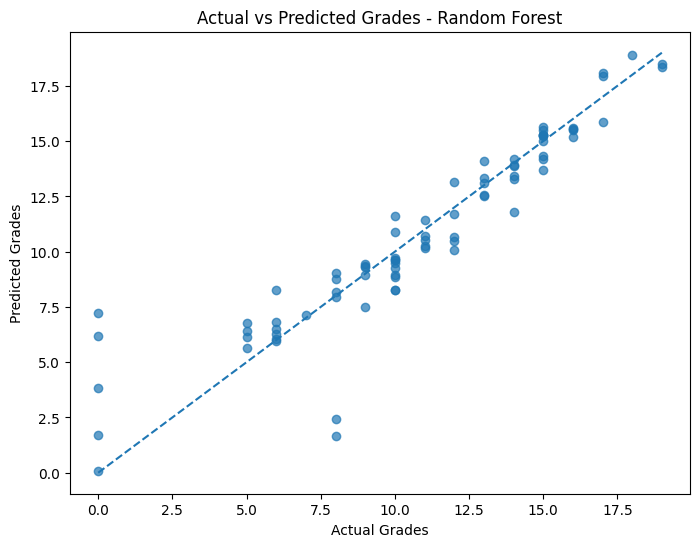

In [134]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades - Random Forest")

plt.show()

Residual Analysis

Residual analysis helps evaluate how well the Random Forest model predicts student final grades by examining the differences between actual and predicted values.

A residual is calculated as:

$$\text{Residual} = y - \hat{y}$$

Where $y$ represents the Actual Value and $\hat{y}$ represents the Predicted Value.

- Positive residual: The model underpredicted the student's actual grade.
- Negative residual: The model overpredicted the student's actual grade.
- Residual close to zero: The prediction was close to the actual grade.

Residual analysis is performed using:

1. Residual Scatter Plot: Examines the distribution of residuals and helps identify patterns or unusually large prediction errors.
2. Residual Distribution Histogram: Shows how frequently different residual values occur and whether the errors are approximately centred around zero.

The analysis helps identify systematic prediction errors and assess the model's overall behaviour. Since Random Forest is a tree-based model, normally distributed residuals are not a strict requirement.

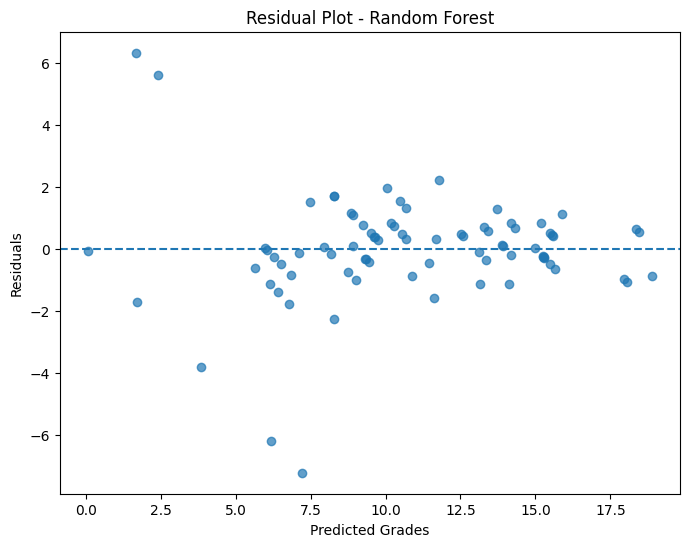

In [135]:
residuals = y_test - y_pred_rf

plt.figure(figsize=(8, 6))
plt.scatter(y_pred_rf, residuals, alpha=0.7)
plt.axhline(y=0, linestyle='--')
plt.xlabel("Predicted Grades")
plt.ylabel("Residuals")
plt.title("Residual Plot - Random Forest")
plt.show()

Error Analysis

Error analysis examines individual predictions to identify cases where the Random Forest model performs poorly.

While overall evaluation metrics such as MAE and RMSE describe the model's general performance, analysing individual errors helps reveal specific situations in which predictions differ significantly from actual grades.

In this section, the prediction errors are calculated and the observations with the largest absolute errors are identified.

The analysis focuses on:

- Actual Grade: The student's actual final grade.
- Predicted Grade: The grade estimated by the model.
- Residual: The difference between the actual and predicted grades.
- Absolute Error: The magnitude of the prediction error, regardless of its direction.

This analysis helps identify students whose grades were particularly difficult for the model to predict and highlights potential limitations of the model.

In [136]:
error_analysis = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_rf,
    'Residual': residuals
})

error_analysis['Absolute_Error'] = error_analysis['Residual'].abs()

error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
).head(5)

,Actual,Predicted,Residual,Absolute_Error
140,0,7.226667,-7.226667,7.226667
90,8,1.676667,6.323333,6.323333
316,0,6.193333,-6.193333,6.193333
124,8,2.410000,5.590000,5.590000
334,0,3.830000,-3.830000,3.830000


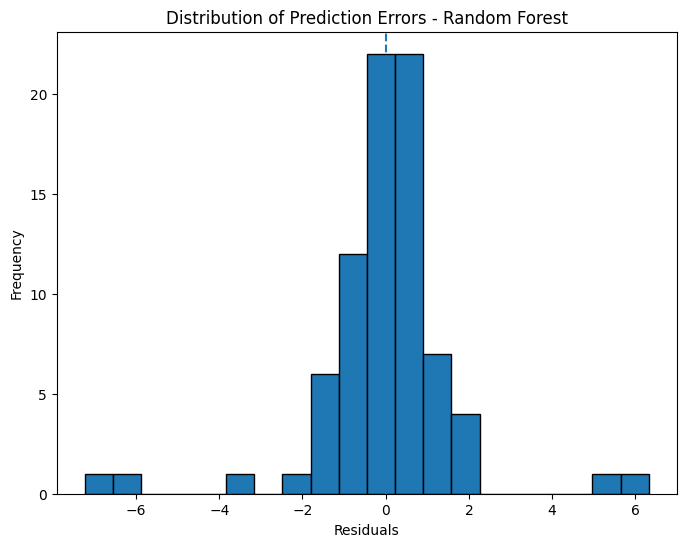

In [137]:
plt.figure(figsize=(8, 6))

plt.hist(residuals, bins=20, edgecolor='black')

plt.axvline(0, linestyle='--')

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors - Random Forest")

plt.show()

Model Stability Analysis Using Repeated Train-Test Splits

A model's performance can vary depending on how the dataset is divided into training and testing sets. To examine this variation, the Random Forest model is evaluated using multiple train-test splits with different random states.

In this experiment, the dataset is split into training and testing sets 10 times using different random states while keeping the test size at 20%.

For each split, the model is trained and evaluated using three performance metrics:

- Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted grades.
- Root Mean Squared Error (RMSE): Measures prediction error while giving greater weight to larger errors.
- R² Score: Measures how much variation in final grades is explained by the model.

The mean and standard deviation of these metrics are calculated across all 10 experiments.

This experiment helps assess the stability and consistency of model performance across different data splits. However, all experiments use the same dataset, so the results do not represent validation on an independent dataset.

In [138]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

split_results = []

for seed in range(10):
    X_train_temp, X_test_temp, y_train_temp, y_test_temp = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )

    model = RandomForestRegressor(
        n_estimators=300,
        random_state=42
    )

    model.fit(X_train_temp, y_train_temp)

    predictions = model.predict(X_test_temp)

    split_results.append({
        'Random_State': seed,
        'MAE': mean_absolute_error(y_test_temp, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test_temp, predictions)),
        'R2': r2_score(y_test_temp, predictions)
    })

split_results = pd.DataFrame(split_results)

split_results

,Random_State,MAE,RMSE,R2
0,0,1.034557,1.762655,0.887384
1,1,0.977173,1.417569,0.853019
2,2,0.924641,1.504681,0.881473
3,3,0.992743,1.478354,0.908501
4,4,0.852194,1.400123,0.913665
5,5,1.230338,1.804571,0.843695
6,6,1.001730,1.625765,0.882394
7,7,0.905359,1.573816,0.841137
8,8,0.885443,1.213898,0.933850
9,9,0.925949,1.645245,0.786090


In [139]:
split_results[['MAE', 'RMSE', 'R2']].agg(['mean', 'std'])

,MAE,RMSE,R2
mean,0.973013,1.542668,0.873121
std,0.106788,0.177958,0.043218


Random Forest Learning Curve

A learning curve is used to understand how a machine learning model's performance changes as the amount of training data increases.

In this experiment, a learning curve is generated for the Random Forest Regressor by evaluating its performance on different training-set sizes.

The curve compares two scores:

- Training Score: Measures model performance on the data used for training.
- Validation Score: Measures model performance on unseen validation folds.

The learning curve helps identify potential issues such as:

- Overfitting: The training score is significantly higher than the validation score.
- Underfitting: Both training and validation scores are relatively low.
- Generalization: Training and validation scores are close and reasonably high.

By examining how the validation score changes with increasing training data, we can understand whether additional training samples might improve the model's performance.

This experiment provides further insight into the Random Forest model's ability to generalize beyond its training data.

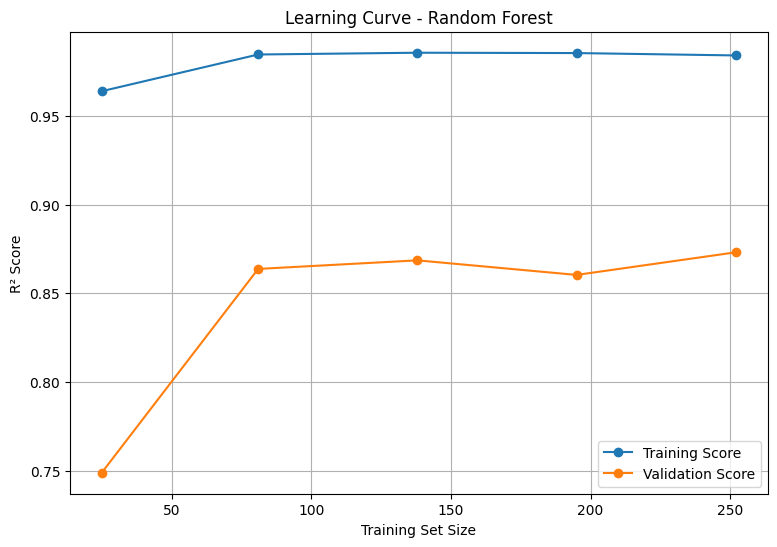

In [140]:
from sklearn.model_selection import learning_curve, KFold
from sklearn.ensemble import RandomForestRegressor

rf_learning = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, validation_scores = learning_curve(
    rf_learning,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=cv_strategy,
    scoring='r2',
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(train_sizes, train_mean, marker='o', label='Training Score')
plt.plot(train_sizes, validation_mean, marker='o', label='Validation Score')

plt.xlabel("Training Set Size")
plt.ylabel("R² Score")
plt.title("Learning Curve - Random Forest")
plt.legend()
plt.grid()

plt.show()

Final Model Performance Summary

The following table provides a consolidated comparison of the regression models evaluated in this project.

The models are compared using three evaluation metrics:

- MAE (Mean Absolute Error): Lower values indicate smaller average prediction errors.
- RMSE (Root Mean Squared Error): Lower values indicate better prediction accuracy, with larger errors receiving greater weight.
- $R^2$ Score: Higher values indicate that the model explains a greater proportion of the variation in final grades.

| Model | MAE | RMSE | $R^2$ Score |
| :--- | :---: | :---: | :---: |
| Linear Regression | 1.3482 | 2.1222 | 0.7804 |
| Ridge Regression | 1.3474 | 2.1214 | 0.7805 |
| Lasso Regression | 1.2688 | 2.0828 | 0.7884 |
| Random Forest | 1.0482 | 1.7359 | 0.8530 |
| Tuned Random Forest | 1.0696 | 1.7417 | 0.8521 |
| Early Prediction Random Forest | 3.3248 | 4.0275 | 0.2089 |

Best Performing Model

The original Random Forest Regressor achieved the strongest overall performance among these six models, with an MAE of 1.0482, RMSE of 1.7359 and $R^2$ score of 0.8530.

The early prediction model performed considerably worse, demonstrating the importance of previous-period grades ("G1" and "G2") in predicting final Mathematics grades.

Project Conclusion

This project explored the application of machine learning techniques to predict students' final Mathematics grades ("G3") using the UCI Student Performance dataset.

The workflow included data inspection, data cleaning, exploratory data analysis, correlation analysis, multicollinearity assessment, feature selection, model training, hyperparameter optimization, and model evaluation.

Several regression algorithms were implemented and compared:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Random Forest Regression
- Hyperparameter-tuned Random Forest
- Early Prediction Random Forest (excluding "G1" and "G2")

Key Findings

1. The original Random Forest model achieved the strongest overall performance among the evaluated models, with an MAE of approximately 1.05, RMSE of 1.74, and R² of 0.853.
2. The previous-period grades, particularly "G2", were highly influential in predicting the final grade.
3. The early prediction model performed considerably worse after excluding "G1" and "G2", highlighting the difficulty of predicting final performance without previous academic results.
4. Hyperparameter tuning did not produce a meaningful improvement over the original Random Forest model.
5. Repeated train-test splits and learning-curve analysis provided additional insight into the model's stability and generalization behaviour.
6. Residual and error analysis helped identify individual predictions where the model performed poorly.

Limitations

- The dataset contains only 395 student records, which limits the amount of information available for training.
- The strong influence of "G2" means the original model is more suitable for predicting final grades when second-period grades are already available.
- The early prediction model is more relevant when previous-period grades are unavailable, but its predictive performance is considerably lower.
- The results are based on a single dataset and should be validated on additional student data before real-world application.
- Feature importance indicates predictive relationships, not necessarily causal relationships.

Final Outcome

The project demonstrates how regression algorithms can be used to analyse student academic performance and estimate final grades. It also highlights the importance of feature selection, proper data splitting, model evaluation, and understanding the limitations of predictive models.

Overall, the Random Forest Regressor provided the best predictive performance in this experiment, while the early prediction experiment demonstrated the challenges of estimating academic outcomes without previous grades.

References and Acknowledgements

The following resources were used as references for this project.

1. Dataset Source

UCI Machine Learning Repository – Student Performance Dataset

Cortez, P. and Silva, A. (2008). Using Data Mining to Predict Secondary School Student Performance.

The dataset contains student demographic, social and academic information and was used to develop regression models for predicting final Mathematics grades.

Dataset: https://archive.ics.uci.edu/dataset/320/student+performance

2. Python Libraries

The following Python libraries were used for data analysis, visualization and machine learning:

- Pandas: Data manipulation and analysis.
- NumPy: Numerical computations.
- Matplotlib: Data visualization.
- Seaborn: Statistical data visualization.
- Scikit-learn: Data preprocessing, feature selection, model training, hyperparameter tuning and evaluation.

3. Documentation

Official documentation:

- Pandas: https://pandas.pydata.org/docs/
- NumPy: https://numpy.org/doc/
- Matplotlib: https://matplotlib.org/stable/
- Seaborn: https://seaborn.pydata.org/
- Scikit-learn: https://scikit-learn.org/stable/

Acknowledgement

This project was developed for educational purposes to understand and implement the complete machine learning workflow, from data exploration and preprocessing to model development, evaluation and interpretation.